# 10주차 · 고급 정렬 구현 및 비교
## 학생용 — TODO 구현·실험·분석
데이터구조 | 임화정 | 2026-2

목표: 병합·빠른·기수 정렬 구현, 분할정복과 비비교 정렬 구분, 안정성·복잡도 분석, 입력 유형별 공정한 비교.



In [17]:
import random, time, statistics, csv
from collections import Counter
SEED = 2026
print("Python 3.8+ / Jupyter / Colab")

Python 3.8+ / Jupyter / Colab


## 공통 계약과 차이
세 함수는 정렬된 리스트를 반환한다. 병합·기수는 새 리스트를 반환하며 원본 유지; 빠른 정렬은 원본 수정 후 동일 리스트 반환. 인터페이스 차이를 숨기지 않는다. key 함수는 결정적이어야 한다. 직접 구현에서는 sorted/list.sort 금지; 정답 검증에만 허용.
기수 정렬 범위: **0 이상의 Python int 키**. 음수/실수/bool은 ValueError. 일반 비교정렬을 대체하는 만능 알고리즘이 아니다.

## merge_sort
분할→재귀 정렬→병합. 동점에서 왼쪽을 먼저 선택(<=). 불변식: out은 처리한 원소를 정렬된 순서로 담는다.

In [18]:
def merge_sort(a, key=lambda x: x):
    if len(a) <= 1:
        return a.copy()
    mid = len(a) // 2
    left = merge_sort(a[:mid], key)
    right = merge_sort(a[mid:], key)
    out = []
    i = j = 0
    while i < len(left) and j < len(right):
        if key(left[i]) <= key(right[j]):
            out.append(left[i])
            i += 1
        else:
            out.append(right[j])
            j += 1
    out.extend(left[i:])
    out.extend(right[j:])
    return out

## quick_sort
중간 위치 원소를 끝으로 이동한 Lomuto 분할. 중간 위치는 중앙값이 아니다. 작은 구간 먼저 처리/큰 구간 보류로 스택 O(log n). <=가 중복을 한쪽으로 몰아 최악 Θ(n²).

In [19]:
from os import pwritev
from IPython.core.alias import re
def quick_sort(a, key=lambda x: x):
    if len(a) < 2:
        return a
    stack = [(0, len(a) - 1)]
    while stack:
        lo, hi = stack.pop()
        while lo < hi:
            m = (lo + hi) // 2
            a[m], a[hi] = a[hi], a[m]
            pivot = key(a[hi])
            i = lo
            for j in range(lo, hi):
                if key(a[j]) <= pivot:
                    a[i], a[j] = a[j], a[i]
                    i += 1
            a[i], a[hi] = a[hi], a[i]
            if i - lo < hi - i:
                if i + 1 < hi:
                    stack.append((i + 1, hi))
                hi = i - 1
            else:
                if lo < i - 1:
                    stack.append((lo, i - 1))
                lo = i + 1
    return a

## radix_sort
10진 LSD: 일의 자리부터 각 자리의 안정적 버킷 정렬. 각 패스 이후 낮은 k자리 기준 정렬. 입력 순서대로 버킷에 넣어 안정성 유지.

In [20]:
def radix_sort(a, key=lambda x: x):
    out = a.copy()
    keys = [key(x) for x in out]
    if any(type(k) is not int or k < 0 for k in keys):
        raise ValueError("key must be a non-negative integer")
    if not out:
        return out
    maximum = max(keys)
    exp = 1
    while maximum // exp > 0:
        buckets = [[] for _ in range(10)]
        for value in out:
            digit = (key(value) // exp) % 10
            buckets[digit].append(value)
        out = [x for bucket in buckets for x in bucket]
        exp *= 10
    return out

## 1. 정확성 및 인터페이스 테스트
빈/단일/중복/정렬/역순/무작위·음수와 기수 제약 검증.

In [21]:
algorithms = {"Merge": merge_sort, "Quick": quick_sort, "Radix": radix_sort}
ready = {}
for name, fn in algorithms.items():
    try:
        rng = random.Random(SEED)
        cases = [[], [0], [2,1], [3,3,3], list(range(20)), list(range(20,-1,-1))]
        cases += [[rng.randrange(1000) for _ in range(n)] for n in range(51)]
        for original in cases:
            data = original.copy(); result = fn(data)
            assert result == sorted(original)
            assert Counter(result) == Counter(original)
            if name == "Quick": assert result is data
            else: assert data == original and result is not data
        if name != "Radix":
            assert fn([-5, 2, -1]) == [-5, -1, 2]
        else:
            for bad in [[-1], [1.5], [True]]:
                try: fn(bad)
                except ValueError: pass
                else: raise AssertionError("invalid key accepted")
        ready[name] = fn
        print(name, len(cases), "cases passed")
    except NotImplementedError:
        print(name, "TODO 구현 후 재실행")

Merge 57 cases passed
Quick 57 cases passed
Radix 57 cases passed


## 2. 수기 추적
병합: [5,1,4,2,8]의 분할 트리와 병합 결과를 작성.
빠른: 같은 입력의 첫 분할(중간 pivot=4), 분할 직후 배열과 pivot 인덱스를 작성.
기수: 아래 예제의 일·십·백 자리 결과를 실행 전에 예측.

학생 답안: ___

In [22]:
data = [170,45,75,90,802,24,2,66]
for exp in [1,10,100]:
    buckets = [[] for _ in range(10)]
    for value in data: buckets[(value//exp)%10].append(value)
    data = [value for bucket in buckets for value in bucket]
    print("exp", exp, data)
assert data == [2,24,45,66,75,90,170,802]

exp 1 [170, 90, 802, 2, 24, 45, 75, 66]
exp 10 [802, 2, 24, 45, 66, 170, 75, 90]
exp 100 [2, 24, 45, 66, 75, 90, 170, 802]


## 3. 안정성 검증
키가 같을 때 A/B/C의 원래 순서가 유지되는가? 한 사례 성공이 안정성의 증명은 아니다.

In [23]:
records = [(2,"A"), (2,"B"), (1,"C")]
for name, fn in ready.items():
    result = fn(records.copy(), key=lambda x:x[0])
    print(name, result, "stable in this example:", [x[1] for x in result if x[0]==2] == ["A","B"])
# One successful example cannot prove stability. Find a Quick counterexample.
if "Quick" in ready:
    sample = [(1,"A"),(1,"B"),(1,"C")]
    print("Quick counterexample:", quick_sort(sample.copy(), key=lambda x:x[0]))

Merge [(1, 'C'), (2, 'A'), (2, 'B')] stable in this example: True
Quick [(1, 'C'), (2, 'A'), (2, 'B')] stable in this example: True
Radix [(1, 'C'), (2, 'A'), (2, 'B')] stable in this example: True
Quick counterexample: [(1, 'C'), (1, 'A'), (1, 'B')]


## 4. 복잡도 분석
|알고리즘|최선|평균|최악|보조공간|안정성|
|---|---|---|---|---|---|
|병합(현재 구현)|Θ(n log n)|Θ(n log n)|Θ(n log n)|O(n), 재귀 깊이 O(log n)|안정|
|빠른(현재 구현)|Θ(n log n)|Θ(n log n)*|Θ(n²)|O(log n) 명시적 스택|불안정|
|기수 LSD|O(d(n+b))|O(d(n+b))|O(d(n+b))|O(n+b)|안정|
*평균은 무작위 순열/균형 분할이 기대되는 가정. 최선/평균/최악 비교정렬 표는 일반 n≥2 기준. b=10; d=max(1, 최대키 자릿수). all-zero는 패스0회이지만 초기 복사·검증 Θ(n). 기수 키의 자리 추출 O(1) 가정, 임의 정밀도의 거대 정수에서는 산술 비용 별도. 병합 구현은 슬라이싱/리스트 할당 비용을 포함하며 피크 보조공간 O(n).

질문: 병합 T(n)=2T(n/2)+Θ(n)을 유도. Quick 중복 입력 최악 이유. 기수는 비교정렬 Ω(n log n) 하한을 왜 위반하지 않는가?
학생 답안: ___

## 5. 공정한 성능 비교
고정 시드, 동일 원본, 준비 복사/정답 검증 타이머 밖, 워밍업, 순서 섞기, 5회 중앙값. 함수 내부의 병합/기수 할당은 알고리즘 비용이므로 포함. 공통 key 호출 비용 포함. 4입력×4크기×3구현.
중복에서 현재 Quick은 이차 시간; 매우 큰 n으로 무작정 확장하지 말 것. 기본250~2000 완료 후 무작위/정렬만 단계적으로 확장. 함수 계약·메모리 차이도 분석. 실행환경에 따라 수치 달라짐; 한 실측으로 점근적 복잡도 증명 불가.

In [24]:
def make_data(n, pattern):
    rng = random.Random(SEED+n)
    if pattern == "random": return [rng.randrange(1000000) for _ in range(n)]
    if pattern == "sorted": return list(range(n))
    if pattern == "reverse": return list(range(n-1,-1,-1))
    if pattern == "duplicates": return [rng.randrange(5) for _ in range(n)]
    raise ValueError(pattern)
SIZES = [250,500,1000,2000]
PATTERNS = ["random","sorted","reverse","duplicates"]
REPEATS = 5
results = []
if len(ready) != 3:
    print("세 구현과 테스트 완료 후 다시 실행하세요.")
else:
    for pattern in PATTERNS:
        for n in SIZES:
            data = make_data(n, pattern); expected = sorted(data)
            samples = {name:[] for name in ready}
            for fn in ready.values(): fn(data.copy())
            rng = random.Random(SEED+n)
            for _ in range(REPEATS):
                order = list(ready); rng.shuffle(order)
                for name in order:
                    a = data.copy()  # Preparation outside timer.
                    start = time.perf_counter_ns()
                    result = ready[name](a)
                    elapsed = time.perf_counter_ns()-start
                    assert result == expected
                    samples[name].append(elapsed/1000000)
            for name, values in samples.items():
                results.append(dict(pattern=pattern,n=n,algorithm=name,median_ms=statistics.median(values)))
    with open("week10_benchmark.csv","w",newline="",encoding="utf-8-sig") as f:
        w=csv.DictWriter(f,fieldnames=list(results[0]));w.writeheader();w.writerows(results)
    for row in results[:6]: print(row)
    print(len(results), "rows saved")

{'pattern': 'random', 'n': 250, 'algorithm': 'Merge', 'median_ms': 0.58156}
{'pattern': 'random', 'n': 250, 'algorithm': 'Quick', 'median_ms': 0.45101}
{'pattern': 'random', 'n': 250, 'algorithm': 'Radix', 'median_ms': 0.310824}
{'pattern': 'random', 'n': 500, 'algorithm': 'Merge', 'median_ms': 1.476709}
{'pattern': 'random', 'n': 500, 'algorithm': 'Quick', 'median_ms': 0.744554}
{'pattern': 'random', 'n': 500, 'algorithm': 'Radix', 'median_ms': 0.558489}
48 rows saved


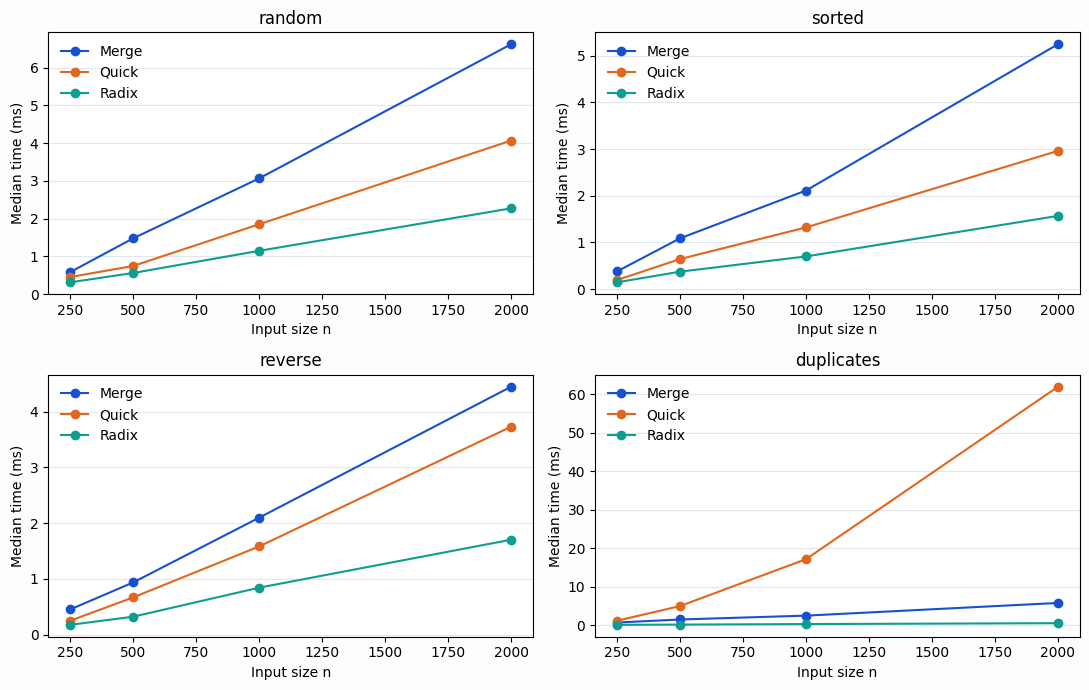

In [25]:
if results:
    try:
        import matplotlib.pyplot as plt
        fig, axes = plt.subplots(2,2,figsize=(11,7),facecolor="#FDFDFF")
        colors = ["#1751D0","#E2661E","#0E9E8F"]
        for ax, pattern in zip(axes.flat,PATTERNS):
            for color,name in zip(colors,algorithms):
                rows=[r for r in results if r["pattern"]==pattern and r["algorithm"]==name]
                ax.plot([r["n"] for r in rows],[r["median_ms"] for r in rows],marker="o",color=color,label=name)
            ax.set(title=pattern,xlabel="Input size n",ylabel="Median time (ms)")
            ax.grid(axis="y",color="#E2E6F0");ax.set_axisbelow(True);ax.legend(frameon=False)
        fig.tight_layout();fig.savefig("week10_benchmark.png",dpi=150);plt.show()
    except ImportError: print("matplotlib 없음: CSV로 분석하세요.")
else: print("먼저 구현 및 측정을 완료하세요.")

## 6. 프로젝트 분석 및 제출
1. 각 유형별 승자와 그 이유를 실측 근거로 설명.
2. T(2n)/T(n)과 이론 비교(정확히2/4가 아니어도 정상).
3. 무작위 입력의 숫자 범위를10^3/10^6/10^9로 바꿔 기수 자릿수 효과 실험. n과 d를 분리 통제.
4. Quick 중복 문제를 3-way partition으로 개선하는 확장 설계(선택).
5. 9주차 기본 정렬과 작은 n 비교(이전 함수 직접 가져오기).
6. 시간 외 메모리/안정성/키 제한을 포함해 선택 근거 작성.

답안: 표___ / 그래프___ / 해석___ / 제한___
DS_10A.ipynb: 실행된 ipynb, 분석문 추가하여 lms 제출